In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import pandas as pd
import plotly.express as px


# Connect to the local drive to read the data file
from google.colab import drive
drive.mount('/content/drive')
folder_path = '/content/drive/MyDrive/Colab Notebooks'
file_path = '/data/coupons.csv'

Mounted at /content/drive


In [2]:
# =============================================
# 1 Read the CSV file into the dataframe
# =============================================
masterdata = pd.read_csv(folder_path+file_path)

In [3]:
masterdata.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


In [4]:
# ============================================================
# 2. UNDERSTAND THE DATA for missing or problematic data.
# ============================================================

print("\n==============================")
print("DATASET INFORMATION")
print("==============================")

print("Orders shape:", masterdata.shape)
# Rename the column that has "Y" as the name to "couponUsed"
masterdata = masterdata.rename(columns={'Y': 'CouponUsed'})

# Fixing the spelling of a column
masterdata = masterdata.rename(columns={'passanger': 'passenger'})


 # ============================================================
 # Examine Coupon acceptance data
 # ============================================================
print("Coupon counts:", masterdata['CouponUsed'].value_counts())

# =============================================================
# Checking for missing data
# =============================================================
print("Checking null values in each column", masterdata.isna().sum())
print("\nColumn Car has no values and we can't assume the type of car to assume luxury or not.  It is missing data")





DATASET INFORMATION
Orders shape: (12684, 26)
Coupon counts: CouponUsed
1    7210
0    5474
Name: count, dtype: int64
Checking null values in each column destination                 0
passenger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
CouponUsed                  0
dtype: int64

Column Car has no values and we can't assume the ty

passenger counts: passenger
Alone        7305
Friend(s)    3298
Partner      1075
Kid(s)       1006
Name: count, dtype: int64
weather counts: weather
Sunny    10069
Snowy     1405
Rainy     1210
Name: count, dtype: int64
temperature counts: temperature
80    6528
55    3840
30    2316
Name: count, dtype: int64
time counts: time
6PM     3230
7AM     3164
10AM    2275
2PM     2009
10PM    2006
Name: count, dtype: int64
coupon counts: coupon
Coffee House             3996
Restaurant(<20)          2786
Carry out & Take away    2393
Bar                      2017
Restaurant(20-50)        1492
Name: count, dtype: int64
expiration counts: expiration
1d    7091
2h    5593
Name: count, dtype: int64
gender counts: gender
Female    6511
Male      6173
Name: count, dtype: int64
age counts: age
21         2653
26         2559
31         2039
50plus     1788
36         1319
41         1093
46          686
below21     547
Name: count, dtype: int64
maritalStatus counts: maritalStatus
Married partner    

<Axes: title={'center': 'Coupon vs Age'}, xlabel='coupon', ylabel='count'>

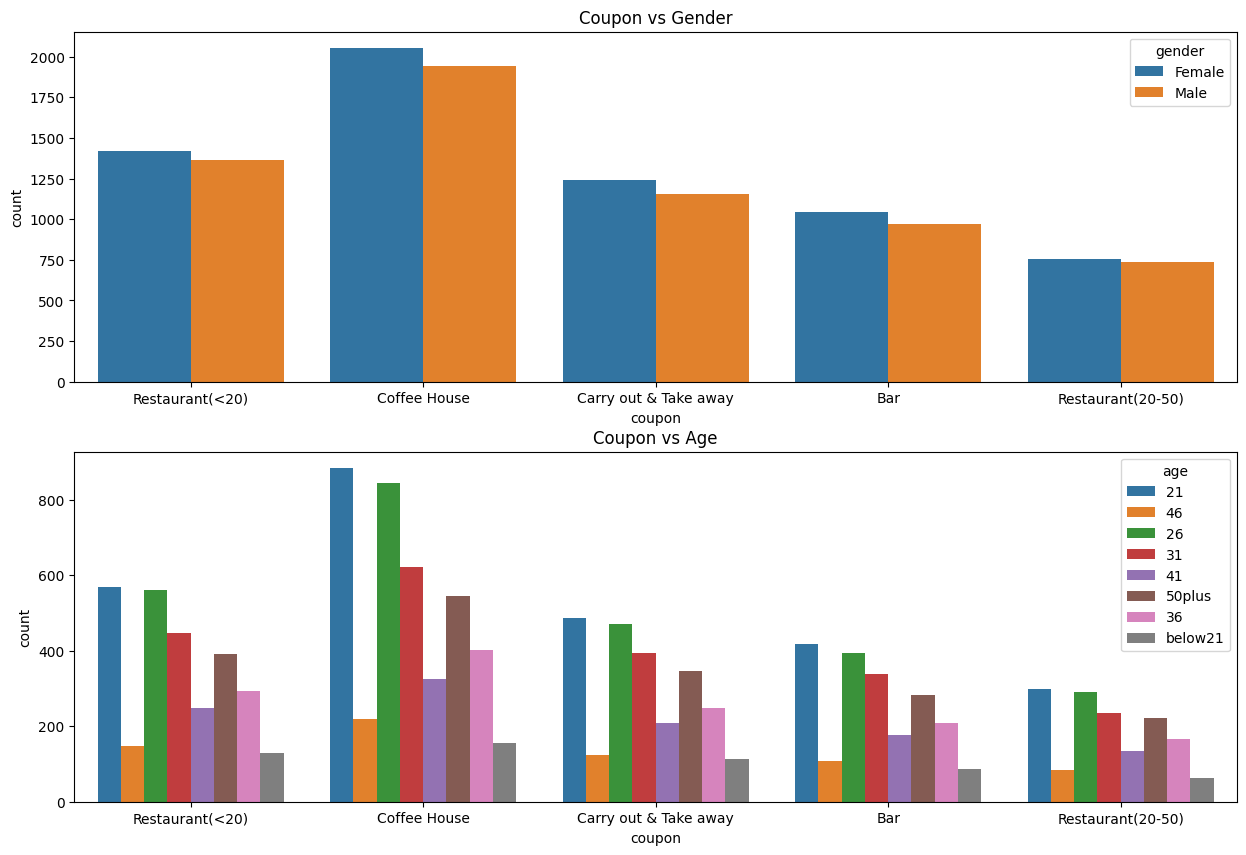

In [7]:
# Analyze the data
print("passenger counts:", masterdata['passenger'].value_counts())
print("weather counts:", masterdata['weather'].value_counts())
print("temperature counts:", masterdata['temperature'].value_counts())
print("time counts:", masterdata['time'].value_counts())
print("coupon counts:", masterdata['coupon'].value_counts())
print("expiration counts:", masterdata['expiration'].value_counts())
print("gender counts:", masterdata['gender'].value_counts())
print("age counts:", masterdata['age'].value_counts())
print("maritalStatus counts:", masterdata['maritalStatus'].value_counts())
print("CoffeeHouse counts:", masterdata['CoffeeHouse'].value_counts())
print("CarryAway counts:", masterdata['CarryAway'].value_counts())
print("Bar counts:", masterdata['Bar'].value_counts())


plt.figure(figsize = (15,10))
plt.subplot(211)
sns.countplot(masterdata, x='coupon', hue='gender')
plt.title('Coupon vs Gender')

plt.subplot(212)
plt.title("Coupon vs Age")
sns.countplot(masterdata, x='coupon', hue='age')



In [8]:
# Replace NaN with never so we can run our analysis
print("\nMaking other NaN to No where values don't exist and since the pct of this data is less than 1 pct, it should not change overall results")
masterdata = masterdata.fillna('never')



Making other NaN to No where values don't exist and since the pct of this data is less than 1 pct, it should not change overall results


<Axes: title={'center': 'Coupon Usage Distribution'}, ylabel='count'>

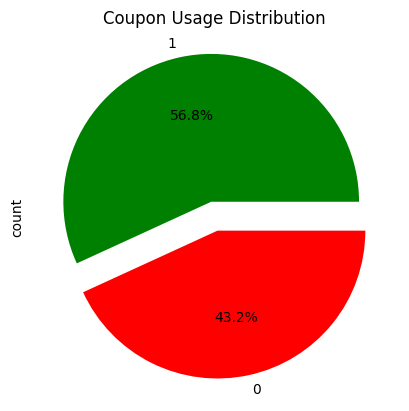

In [9]:

# ==============================================================================
# Plotting data of the total observations chose to accept the coupon
# ==============================================================================
masterdata['CouponUsed'].value_counts().plot(kind='pie', explode = [0.1, 0.1],
                                     autopct ='%1.1f%%', colors = ['g', 'r'],
                                             title='Coupon Usage Distribution')

In [10]:
# check the cross tab for these two variables
pd.crosstab(masterdata['CouponUsed'], masterdata['gender'],
            normalize = True)*100

# ============================================================================
# Plotting the Coupons across variuos types
# ============================================================================
px.bar(masterdata.groupby("coupon")['CouponUsed'].sum().reset_index(),
       x="coupon", y = "CouponUsed" , title='Coupons for various purposes')


In [11]:

# Visualize the temperature column
px.histogram(masterdata, x='temperature', nbins=20, title='Temperature Counts')

In [12]:

bar_coupons = None
# Create a dataframe just of Bar type of coupons
bar_coupons = masterdata[masterdata['coupon'] == 'Bar'].copy()

print(f"Shape of bar_coupons: {bar_coupons.shape}")
print(bar_coupons['coupon'].value_counts())
bar_coupons.head()

Shape of bar_coupons: (2017, 26)
coupon
Bar    2017
Name: count, dtype: int64


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,CouponUsed
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


<Axes: title={'center': 'Bar Coupon Usage'}, ylabel='count'>

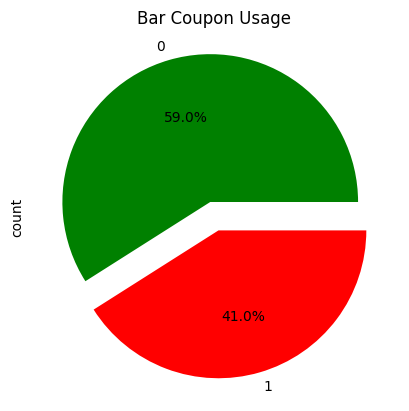

In [13]:
# Plot the bar coupone accepted vs not
bar_coupons['CouponUsed'].value_counts().plot(kind='pie', explode = [0.1, 0.1],
                                     autopct ='%1.1f%%', colors = ['g', 'r'],
                                              title='Bar Coupon Usage')

Acceptance Rate (3 or fewer visits/month): 37.07%
Acceptance Rate (More than 3 visits/month): 76.88%






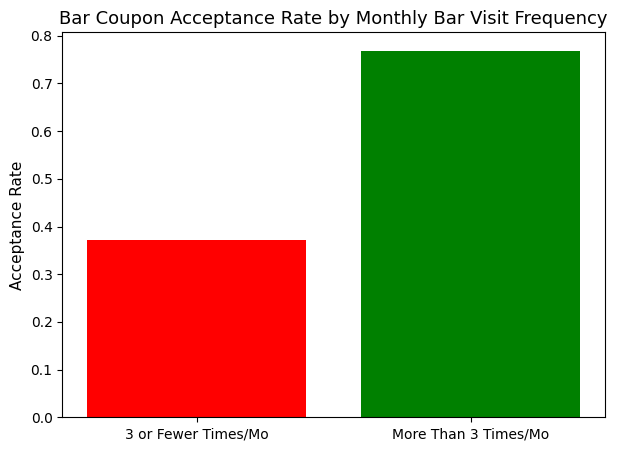

In [15]:
# 1. categories for 3 or fewer bar visits
few_visits = ['never', 'less1', '1~3']

# 'gt8' or '>8' set
more_visits = ['4~8', 'gt8']

# 2. who went to a bar 3 or fewer times a month
group_3_or_less = bar_coupons[bar_coupons['Bar'].isin(few_visits)]
group_more_than_3 = bar_coupons[bar_coupons['Bar'].isin(more_visits)]

# 3. Calculate acceptance rates (mean of binary target column 'CouponUsed')
rate_3_or_less = group_3_or_less['CouponUsed'].mean()
rate_more_than_3 = group_more_than_3['CouponUsed'].mean()

# 4. Display results
print(f"Acceptance Rate (3 or fewer visits/month): {rate_3_or_less:.2%}")
print(f"Acceptance Rate (More than 3 visits/month): {rate_more_than_3:.2%}")

print("\n\n\n")

# Visualization comparing acceptance rates
plt.figure(figsize=(7, 5))
plt.bar(['3 or Fewer Times/Mo', 'More Than 3 Times/Mo'],
        [rate_3_or_less, rate_more_than_3],
        color=['r', 'g'])

plt.title('Bar Coupon Acceptance Rate by Monthly Bar Visit Frequency', fontsize=13)
plt.ylabel('Acceptance Rate', fontsize=11)
plt.show()



In [18]:
# 1. Define conditions for the target group
# Visits more than once a month: ['1~3', '4~8', 'gt8']
frequent_bar_visits = ['1~3', '4~8', 'gt8']

# Age over 25: Exclude '21' and 'below21'
# Standard  categories: ('below21', '21', '26', '31', '36', '41', '46', '50plus')
young_ages = ['21', 'below21']

# 2. drivers who go to a bar more than once a month and are over the age of 25
condition = (
    bar_coupons['Bar'].isin(frequent_bar_visits) &
    (~bar_coupons['age'].isin(young_ages))
)

# 3. Separate into Target Group vs. All Others
target_group = bar_coupons[condition]
all_others = bar_coupons[~condition]

# 4. Calculate acceptance rates
rate_target = target_group['CouponUsed'].mean()
rate_others = all_others['CouponUsed'].mean()

# 5. Display results
print(f"Target Group (Bar > 1/mo & Age > 25) Acceptance Rate: {rate_target:.2%}")
print(f"All Others Acceptance Rate:                           {rate_others:.2%}")

# Percentage Point Difference
diff = rate_target - rate_others
print(f"Difference:                                           {diff:.2%}")

Target Group (Bar > 1/mo & Age > 25) Acceptance Rate: 69.52%
All Others Acceptance Rate:                           33.50%
Difference:                                           36.02%


In [19]:
# 1. Category subsets
frequent_bar_visits = ['1~3', '4~8', 'gt8']
non_child_passengers = ['Friend(s)', 'Partner']
excluded_occupations = ['Farming Fishing & Forestry']

# 2. drivers who go to bars more than once a month and had passengers
# that were not a kid and had occupations other than farming, fishing, or forestry.
condition = (
    bar_coupons['Bar'].isin(frequent_bar_visits) &
    bar_coupons['passenger'].isin(non_child_passengers) &
    (~bar_coupons['occupation'].isin(excluded_occupations))
)

# 3. Separate into Target Segment vs. All Others
target_segment = bar_coupons[condition]
all_others = bar_coupons[~condition]

# 4. Calculate acceptance rates
rate_target = target_segment['CouponUsed'].mean()
rate_others = all_others['CouponUsed'].mean()

# 5. Output comparison metrics
print(f"Target Segment Acceptance Rate: {rate_target:.2%}")
print(f"All Others Acceptance Rate:     {rate_others:.2%}")
print(f"Difference:                     {rate_target - rate_others:.2%}")

Target Segment Acceptance Rate: 71.79%
All Others Acceptance Rate:     37.71%
Difference:                     34.09%


In [20]:
# 1. Define criteria helper lists
frequent_bar = ['1~3', '4~8', 'gt8']
non_kid_passengers = ['Friend(s)', 'Partner']
young_ages = ['below21', '21', '26']
frequent_cheap_dining = ['4~8', 'gt8']
low_income = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']


# 2. Build individual conditions
# Condition 1: go to bars more than once a month, had passengers that were not a kid, and were not widowed
cond1 = (bar_coupons['Bar'].isin(frequent_bar) &
    bar_coupons['passenger'].isin(non_kid_passengers) &
    (bar_coupons['maritalStatus'] != 'Widowed'))

# Condition 2: go to bars more than once a month and are under the age of 30
cond2 = (bar_coupons['Bar'].isin(frequent_bar) & bar_coupons['age'].isin(young_ages))

# Condition 3: go to cheap restaurants more than 4 times a month and income is less than 50K.
cond3 = (bar_coupons['RestaurantLessThan20'].isin(frequent_cheap_dining) & bar_coupons['income'].isin(low_income))

# 3. Combine conditions with OR (|)
combined_condition = cond1 | cond2 | cond3

# 4. Filter target group vs all others
cond1_group = bar_coupons[cond1]
cond2_group = bar_coupons[cond2]
cond3_group = bar_coupons[cond3]

# 5. Calculate acceptance rates
rate_cond1 = cond1_group['CouponUsed'].mean()
rate_cond2 = cond2_group['CouponUsed'].mean()
rate_cond3 = cond3_group['CouponUsed'].mean()

# 6. Display results
print(f"1st Group Size:                {len(cond1_group)}")
print(f"1st Group Acceptance Rate:     {rate_cond1:.2%}")
print(f"2nd Group Size:                {len(cond2_group)}")
print(f"2nd Group Acceptance Rate:     {rate_cond2:.2%}")
print(f"3rd Group Size:                {len(cond3_group)}")
print(f"3rd Group Acceptance Rate:     {rate_cond3:.2%}")


1st Group Size:                195
1st Group Acceptance Rate:     71.79%
2nd Group Size:                345
2nd Group Acceptance Rate:     72.17%
3rd Group Size:                344
3rd Group Acceptance Rate:     45.35%



**Based on the data analaysis, here is the hypothesis.**

 1. Drivers who visit bar more than 3 are 40% more likely to accept the coupon

 2. Drivers who visit Bar > 1/mo visited and & Age > 25 are 36% likely to accept the coupon

 3. Drivers who visit Bar drivers who go to bars more than once a month and had passengers
that were not a kid and had occupations other than farming, fishing, or forestry. 34% likely to accept the coupon

 4. When the three groups are compared, 1st and 2nd groups  whereDrivers who go to bars more than once a month, had passengers that were not a kid, and were not widowed have ~72% coupon acceptance where as drivers who
 go to cheap restaurants more than 4 times a month and income is less than 50K. are 45% more likely to accept the coupon

 **Recommendation**: Avoid sending coupons to drivers who visit cheaper restraurants and have low income.

In [21]:
# ================================================================================
# Independent Investigation on Coffee House Coupons and find who acceptsthese coupons
# ================================================================================

CoffeeHouse_coupons = None

# create a copy for Coffee House coupon specific Dataframe
CoffeeHouse_coupons = masterdata[masterdata['coupon'] == 'Coffee House'].copy()

print(f"Shape of CoffeeHouse_coupons: {CoffeeHouse_coupons.shape}")
print(CoffeeHouse_coupons['coupon'].value_counts())
CoffeeHouse_coupons.head()

Shape of CoffeeHouse_coupons: (3996, 26)
coupon
Coffee House    3996
Name: count, dtype: int64


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,CouponUsed
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,0,0,0,1,0
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,0,0,1,0
12,No Urgent Place,Kid(s),Sunny,55,6PM,Coffee House,2h,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,0,0,1,1
15,Home,Alone,Sunny,80,6PM,Coffee House,2h,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,0,0,0,1,0


<Axes: title={'center': 'Coffee House Coupon Usage'}, ylabel='count'>

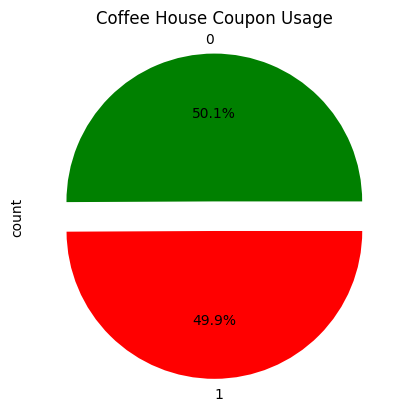

In [22]:
# =============================================================================
# Plotting the pct of coupons accepted vs., not
# =============================================================================

CoffeeHouse_coupons['CouponUsed'].value_counts().plot(kind='pie', explode = [0.1, 0.1],
                                     autopct ='%1.1f%%', colors = ['g', 'r'],
                                                      title='Coffee House Coupon Usage')

Acceptance Rate (1 or never visits/month) : 35.00%
Acceptance Rate (More than 1 visits/month): 66.02%






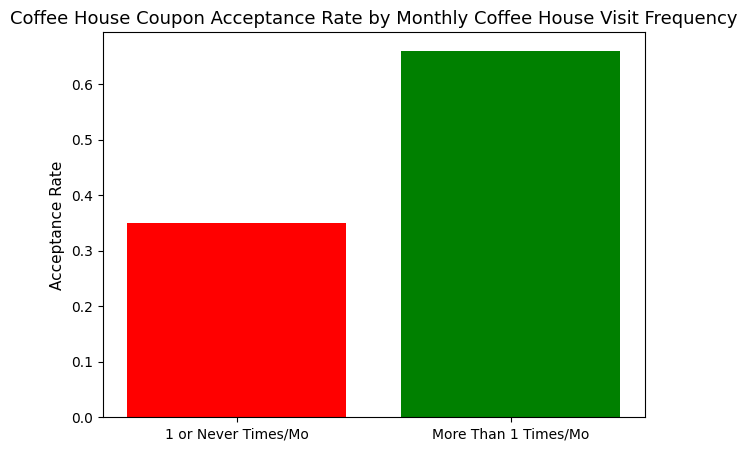

In [23]:
# 1. categories for 1 or fewer Coffee House visits
ch_few_visits = ['never', 'less1']

# more coffee house visits >1
ch_more_visits = ['1~3','4~8', 'gt8']

# 2. who went to a coffee house 1 or never a month
ch_group_1_or_less = CoffeeHouse_coupons[CoffeeHouse_coupons['CoffeeHouse'].isin(ch_few_visits)]
ch_group_more_than_1 = CoffeeHouse_coupons[CoffeeHouse_coupons['CoffeeHouse'].isin(ch_more_visits)]

# 3. Calculate acceptance rates (mean of binary target column 'CouponUsed')
ch_rate_1_or_less = ch_group_1_or_less['CouponUsed'].mean()
ch_rate_more_than_1 = ch_group_more_than_1['CouponUsed'].mean()

# 4. Display results
print(f"Acceptance Rate (1 or never visits/month) : {ch_rate_1_or_less:.2%}")
print(f"Acceptance Rate (More than 1 visits/month): {ch_rate_more_than_1:.2%}")
print("\n\n\n")


# Visualization comparing acceptance rates
plt.figure(figsize=(7, 5))
plt.bar(['1 or Never Times/Mo', 'More Than 1 Times/Mo'],
        [ch_rate_1_or_less, ch_rate_more_than_1],
        color=['r', 'g'])

plt.title('Coffee House Coupon Acceptance Rate by Monthly Coffee House Visit Frequency', fontsize=13)
plt.ylabel('Acceptance Rate', fontsize=11)
plt.show()



In [24]:
# 1. Define conditions for the target group
# Visits more than once a month: ['1~3', '4~8', 'gt8']
frequent_ch_visits = ['1~3', '4~8', 'gt8']

# Age over 25: Exclude 'below21'
# Standard  categories: ('below21', '21', '26', '31', '36', '41', '46', '50plus')
young_ages = ['below21']

# 2. drivers who go to a coffee house more than once a month and are 21 or over the age of 21
ch_condition = (
    CoffeeHouse_coupons['CoffeeHouse'].isin(frequent_ch_visits) &
    (~CoffeeHouse_coupons['age'].isin(young_ages))
)

# 3. Separate into Target Group vs. All Others
ch_target_group = CoffeeHouse_coupons[ch_condition]
ch_all_others   = CoffeeHouse_coupons[~ch_condition]

# 4. Calculate acceptance rates
ch_rate_target = ch_target_group['CouponUsed'].mean()
ch_rate_others = ch_all_others['CouponUsed'].mean()

# 5. Display results
print(f"Target Group (Coffee House > 1/mo & Age >= 21) Acceptance Rate: {ch_rate_target:.2%}")
print(f"All Others Acceptance Rate:                                     {ch_rate_others:.2%}")

# Percentage Point Difference
print(f"Difference:                                                     {ch_rate_target - ch_rate_others:.2%}")

Target Group (Coffee House > 1/mo & Age >= 21) Acceptance Rate: 65.35%
All Others Acceptance Rate:                                     37.23%
Difference:                                                     28.13%


In [28]:
# 1. Category subsets
frequent_ch_visits = ['1~3', '4~8', 'gt8']
ch_non_child_passengers = ['Friend(s)', 'Partner']
excluded_occupations = ['Farming Fishing & Forestry']

# 2. drivers who go to bars more than once a month and had passengers
# that were not a kid and had occupations other than farming, fishing, or forestry.
ch_condition = (
    CoffeeHouse_coupons['CoffeeHouse'].isin(frequent_ch_visits) &
    CoffeeHouse_coupons['passenger'].isin(ch_non_child_passengers) &
    (~CoffeeHouse_coupons['occupation'].isin(excluded_occupations))
)

# 3. Separate into Target Segment vs. All Others
ch_target_segment = CoffeeHouse_coupons[ch_condition]
ch_all_others = CoffeeHouse_coupons[~ch_condition]

# 4. Calculate acceptance rates
ch_rate_target = ch_target_segment['CouponUsed'].mean()
ch_rate_others = ch_all_others['CouponUsed'].mean()

# 5. Output comparison metrics
print(f"Target Segment Acceptance Rate: {ch_rate_target:.2%}")
print(f"All Others Acceptance Rate:     {ch_rate_others:.2%}")
print(f"Difference:                     {ch_rate_target - ch_rate_others:.2%}")



# 1. Define criteria helper lists
# freqfrequent_ch_visits  = ['1~3', '4~8', 'gt8']
# ch_non_child_passengers = ['Friend(s)', 'Partner']
young_ages                = ['below21']
frequent_cheap_dining     = ['4~8', 'gt8']
low_income = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']
high_temp = ['80']

# 2. Build individual conditions
# Condition 1: go to Coffee House more than once a month, had passengers that were not a kid, and were not widowed
cond1 = (CoffeeHouse_coupons['CoffeeHouse'].isin(frequent_ch_visits) &
    CoffeeHouse_coupons['passenger'].isin(ch_non_child_passengers) &
    (CoffeeHouse_coupons['maritalStatus'] != 'Widowed'))

# Condition 2: go to coffee house more than once a month
cond2 = CoffeeHouse_coupons['CoffeeHouse'].isin(frequent_bar)

# Condition 3: Check the temperatuure when it is 80 degrees
cond3 = CoffeeHouse_coupons['temperature'].isin(high_temp)


# 4. Filter target group vs all others
new_ch_cond1_group   = CoffeeHouse_coupons[cond1]
new_ch_cond2_group   = CoffeeHouse_coupons[cond2]
new_ch_cond3_group   = CoffeeHouse_coupons[cond3]

# 5. Calculate acceptance rates
new_ch_rate_cond1  = new_ch_cond1_group['CouponUsed'].mean()
new_ch_rate_cond2  = new_ch_cond2_group['CouponUsed'].mean()
new_ch_rate_cond3  = new_ch_cond3_group['CouponUsed'].mean()

# 6. Display results
print(f"1st Group Size:                {len(new_ch_cond1_group)}")
print(f"1stGroup Acceptance Rate:      {new_ch_rate_cond1:.2%}")
print(f"2nd Group Size:                {len(new_ch_cond2_group)}")
print(f"2nd Group Acceptance Rate:     {new_ch_rate_cond2:.2%}")
print(f"3rd Group Size:                {len(new_ch_cond3_group)}")
print(f"3rd Group Acceptance Rate:     {new_ch_rate_cond3:.2%}")


Target Segment Acceptance Rate: 76.66%
All Others Acceptance Rate:     44.01%
Difference:                     32.65%
1st Group Size:                724
1stGroup Acceptance Rate:      76.66%
2nd Group Size:                1922
2nd Group Acceptance Rate:     66.02%
3rd Group Size:                0
3rd Group Acceptance Rate:     nan%


Based on the data analaysis on Coffee House Specific Coupons, here is the hypothesis.

    Drivers who visit the coffee house more than once are 31% more likely to accept the coupon

    Drivers who visit coffee house > 1/mo visited and & Age >= 21 are 28% likely to accept the coupon

    Drivers who visit the coffeee house  more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry, 32.65% likely to accept the coupon

    Drivers who go to coffee houses more than once a month and had passengers that were not a kid, and were not widowed OR go to Coffee Houses more than once a month and are under the age of 30 accept coupons at 76% and 66% where as
    drivers don't use coupons when it is hot (80 degrees)

    **Recommendations** Don't send coffee house coupons when it is hot outside
